# Infostop Stop Detection

Infostop finds stationary events within `r1` of their running median, then clusters event medians connected within `r2` using Infomap. `dur_min` and `dt_max` are in minutes. Separate visits can share a `location_cluster`. Install the optional dependency with `pip install "nomad[infomap]"`.

This example uses the same Garden City user and day as the other stop detection demos.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

import nomad.data as data_folder
import nomad.io.base as loader
from nomad.stop_detection.infostop import infostop
from nomad.stop_detection.viz import (
    plot_pings, plot_stops, plot_stops_barcode, plot_time_barcode,
)

data_dir = Path(data_folder.__file__).parent
city = gpd.read_parquet(data_dir / "garden-city-buildings-mercator.parquet")
tc = {"user_id": "gc_identifier", "x": "dev_x", "y": "dev_y", "timestamp": "unix_ts"}
traj = loader.sample_from_file(
    data_dir / "gc_data_long", format="parquet", users=["admiring_brattain"],
    filters=("date", "==", "2024-01-01"), traj_cols=tc,
)

In [2]:
stops = infostop(
    traj, r1=20, r2=30, dt_max=60, dur_min=5, complete_output=True, traj_cols=tc,
)

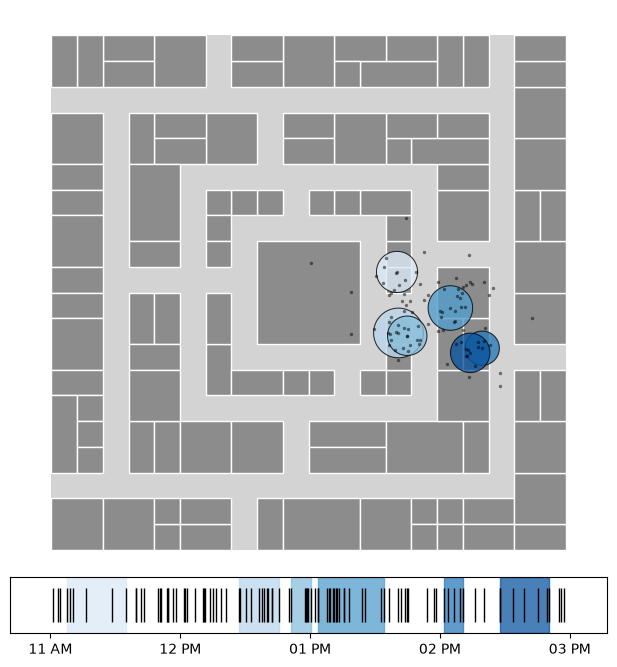

In [3]:
fig, (ax_map, ax_barcode) = plt.subplots(
    2, 1, figsize=(6, 6.5), gridspec_kw={"height_ratios": [10, 1]},
)
gpd.GeoDataFrame(geometry=[box(*city.total_bounds)], crs=city.crs).plot(
    ax=ax_map, color="#d3d3d3",
)
city.plot(ax=ax_map, edgecolor="white", linewidth=1, color="#8c8c8c")
plot_stops(stops, ax=ax_map, cmap="Blues", traj_cols=tc)
plot_pings(traj, ax=ax_map, s=6, color="black", alpha=0.5, traj_cols=tc)
ax_map.set_axis_off()
plot_time_barcode(traj[tc["timestamp"]], ax=ax_barcode, set_xlim=True)
plot_stops_barcode(stops, ax=ax_barcode, cmap="Blues", set_xlim=False, traj_cols=tc)
plt.tight_layout(pad=0.1)
plt.show()